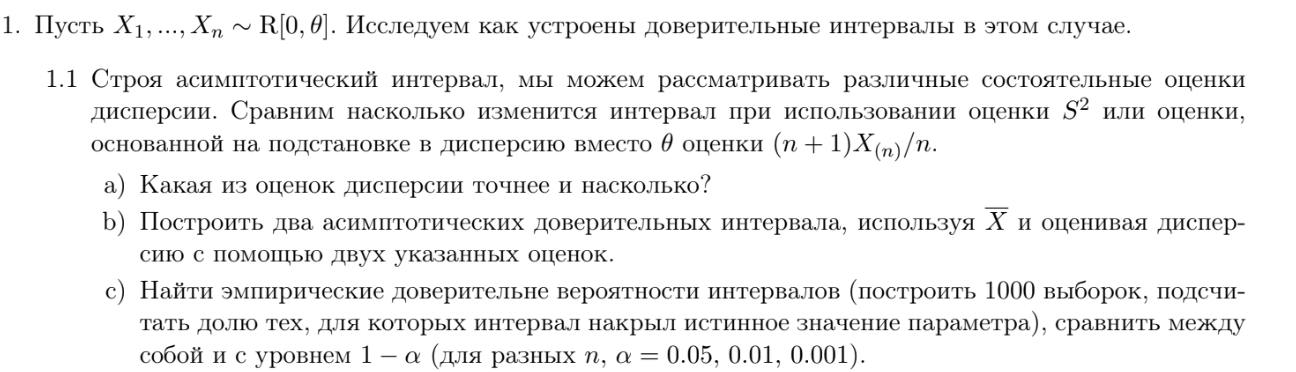

In [ ]:
import numpy as np
from scipy import stats

def solve_task(n=100, theta=10.0, alpha=0.05):

    samples = np.random.uniform(0, theta, (1000, n))

    # Теоретические значения
    z = stats.norm.ppf(1 - alpha / 2)

    # Оценка 1: S^2
    var_s = np.var(samples, axis=1, ddof=1)
    # Оценка 2: через X_(n)
    theta_hat = (n + 1) / n * np.max(samples, axis=1)
    var_sub = (theta_hat**2) / 12

    # Построение интервалов
    x_mean = np.mean(samples, axis=1)

    def get_coverage(var_est):
        lower = 2 * x_mean - z * (2 * np.sqrt(var_est) / np.sqrt(n))
        upper = 2 * x_mean + z * (2 * np.sqrt(var_est) / np.sqrt(n))
        return np.mean((lower <= theta) & (theta <= upper))

    return get_coverage(var_s), get_coverage(var_sub)

# Пример для n=100, alpha=0.05
n_values = [30, 100, 500]
alphas = [0.05, 0.01, 0.001]

print(f"{'n':<6} | {'alpha':<6} | {'Coverage S^2':<15} | {'Coverage Sub':<15}")
for n in n_values:
    for alpha in alphas:
        cov1, cov2 = solve_task(n, 10.0, alpha)
        print(f"{n:<6} | {alpha:<6} | {cov1:<15.4f} | {cov2:<15.4f}")


n      | alpha  | Coverage S^2    | Coverage Sub   
30     | 0.05   | 0.9380          | 0.9460         
30     | 0.01   | 0.9790          | 0.9890         
30     | 0.001  | 0.9970          | 0.9980         
100    | 0.05   | 0.9500          | 0.9500         
100    | 0.01   | 0.9900          | 0.9920         
100    | 0.001  | 0.9990          | 0.9990         
500    | 0.05   | 0.9320          | 0.9320         
500    | 0.01   | 0.9920          | 0.9920         
500    | 0.001  | 1.0000          | 1.0000         


 Оценка дисперсии через θ̂ = (n+1) / n X₍ₙ₎ является более точной в данном случае, так как она использует информацию о границах равномерного распределения, тогда как S² — универсальная оценка, не учитывающая специфику распределения.

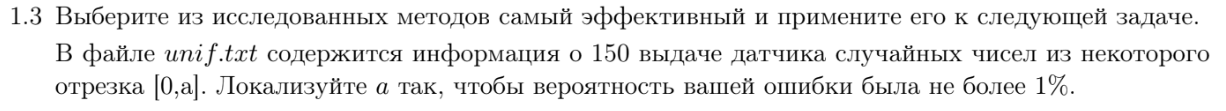

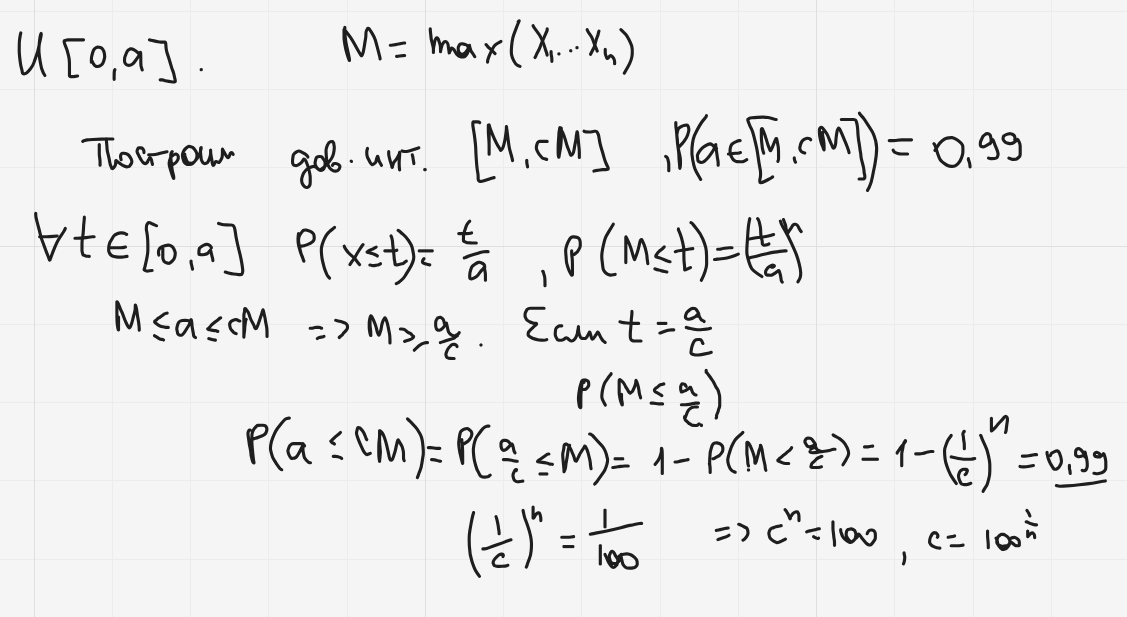

In [3]:
x = np.loadtxt("unif.txt")  # файл с 150 числами, по одному в строке

n = len(x)
m = x.max()

# P(a <= c*M) = 0.99
c = 100 ** (1 / n)
lower = m
upper = c * m

print(f"Максимум выборки: {m:.6f}")
print(f"99%-й интервал для a: [{lower:.6f}, {upper:.6f}]")


Максимум выборки: 4.965686
99%-й интервал для a: [4.965686, 5.120503]


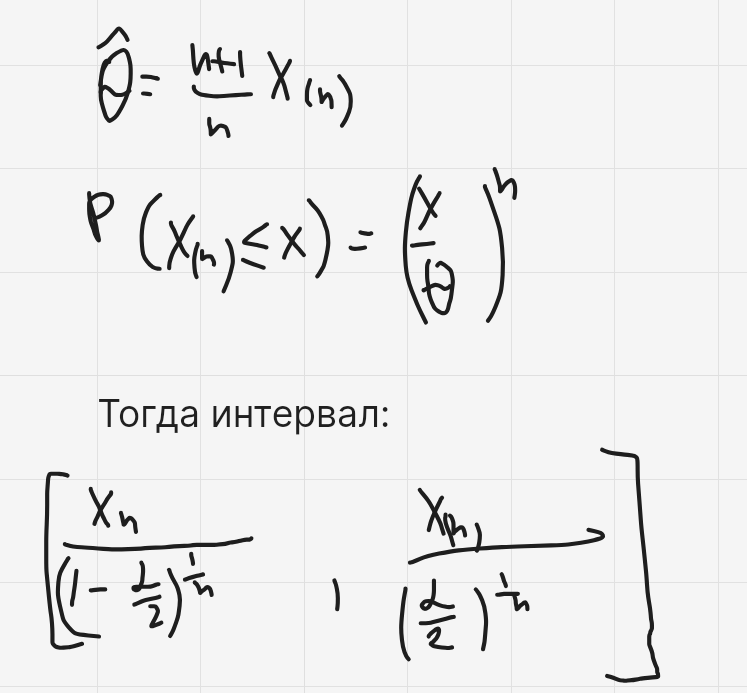

In [6]:
alfa = 0.01
lower=m/(1-alfa/2)**(1/n)
upper=m/(alfa/2)**(1/n)
print(f"99%-й интервал для a: [{lower:.6f}, {upper:.6f}]")

99%-й интервал для a: [4.965852, 5.144219]


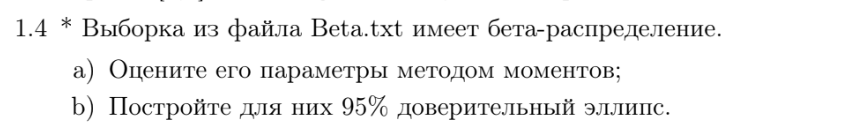

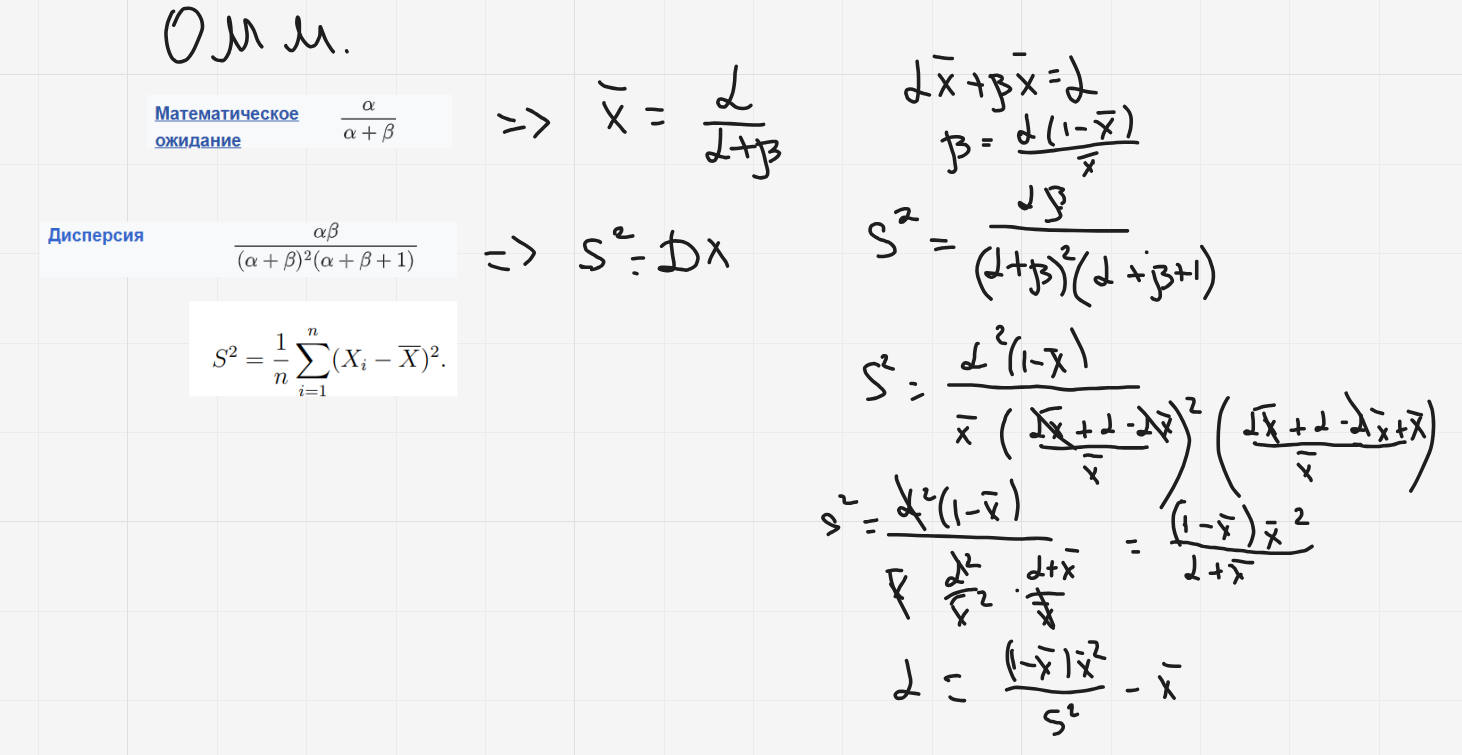

a_hat = 2.225137
b_hat = 3.380641


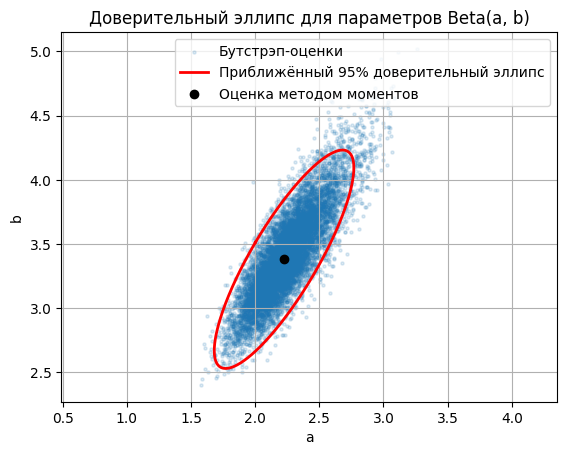

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

x = np.loadtxt("beta.txt").ravel()

def moments_estimate(sample):# ОММ
    mean = np.mean(sample)
    var = np.var(sample, ddof=0)
    a = (1-mean)*mean*mean/var-mean
    b = (1 - mean) * a/mean
    return np.array([a, b])

# Оценки по исходной выборке
ahat, bhat = moments_estimate(x)
print(f"a_hat = {ahat:.6f}")
print(f"b_hat = {bhat:.6f}")

# Параметрический бутстрэп
rng = np.random.default_rng(12345)
B = 10_000
bootstrap_estimates = []

for _ in range(B):
    sample = rng.beta(ahat, bhat, size=len(x))
    try:
        bootstrap_estimates.append(moments_estimate(sample))
    except ValueError:
        pass

bootstrap_estimates = np.asarray(bootstrap_estimates)

# Ковариация бутстрэп-оценок и 95%-й эллипс Вальда
cov = np.cov(bootstrap_estimates, rowvar=False)
cutoff = chi2.ppf(0.95, df=2)

eigenvalues, eigenvectors = np.linalg.eigh(cov)
angles = np.linspace(0, 2 * np.pi, 400)
circle = np.vstack((np.cos(angles), np.sin(angles)))

ellipse = (
    np.array([ahat, bhat])[:, None]
    + eigenvectors
    @ np.diag(np.sqrt(cutoff * eigenvalues))
    @ circle
)

plt.scatter(bootstrap_estimates[:, 0], bootstrap_estimates[:, 1],
            s=5, alpha=0.15, label="Бутстрэп-оценки")
plt.plot(ellipse[0], ellipse[1], "r", linewidth=2,
         label="Приближённый 95% доверительный эллипс")
plt.scatter([ahat], [bhat], color="black", zorder=3,
            label="Оценка методом моментов")

plt.xlabel("a")
plt.ylabel("b")
plt.title("Доверительный эллипс для параметров Beta(a, b)")
plt.legend()
plt.axis("equal")
plt.grid(True)
plt.show()
